In [2]:
# Locate the repository after moving notebooks into notebook/.
from pathlib import Path
import os
import sys

REPO_ROOT = next((path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                  if (path / "main.py").is_file() and (path / "dataset").is_dir()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Start Jupyter from the repository or a directory inside it.")
os.chdir(REPO_ROOT)
for path in (REPO_ROOT, REPO_ROOT / "clean_dataset"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))
(REPO_ROOT / "result/comparisons").mkdir(parents=True, exist_ok=True)


# Model Evaluation And Predictions

Compare two trained models from `summary.csv`, then calculate precision, recall, F1, and confusion matrices from testing prediction CSV files.

## Setup

In [3]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

RESULT_DIR = Path("result")
DATA_FILE = "normalized_zscore_gbm.csv"
DATA_FILE2 = "normalized_zscore_lgg.csv"

# DATA_FILE = "gbm"
# DATA_FILE2 = "lgg"
# DATA_FILE3 = "gbm_own"
# DATA_FILE4 = "lgg_own"

model_summaries = {
    "MLP-GBM": RESULT_DIR / "mlp" / DATA_FILE / "summary.csv",
    "SNN-GBM": RESULT_DIR / "snn" / DATA_FILE / "summary.csv",
    "Gen2Vec-GBM": RESULT_DIR / "gen2vec" / DATA_FILE / "summary.csv",
    "MLP-LGG": RESULT_DIR / "mlp" / DATA_FILE2 / "summary.csv",
    "SNN-LGG": RESULT_DIR / "snn" / DATA_FILE2 / "summary.csv",
    "Gen2Vec-LGG": RESULT_DIR / "gen2vec" / DATA_FILE2 / "summary.csv",
    "ResMLP-GBM": RESULT_DIR / "resmlp" / DATA_FILE / "summary.csv",
    "ResMLP-LGG": RESULT_DIR / "resmlp" / DATA_FILE2 / "summary.csv"
}

# model_summaries = {
#     "MIL-GBM_CLAM": RESULT_DIR / "mil" / DATA_FILE / "summary.csv",
#     "TRANSMIL-GBM_CLAM": RESULT_DIR / "transmil" / DATA_FILE / "summary.csv",
#     "MIL-LGG_CLAM": RESULT_DIR / "mil" / DATA_FILE2 / "summary.csv",
#     "TRANSMIL-LGG_CLAM": RESULT_DIR / "transmil" / DATA_FILE2 / "summary.csv",
#     "MIL-GBM_OWN": RESULT_DIR / "mil" / DATA_FILE3 / "summary.csv",
#     "TRANSMIL-GBM_OWN": RESULT_DIR / "transmil" / DATA_FILE3 / "summary.csv",
#     "MIL-LGG_OWN": RESULT_DIR / "mil" / DATA_FILE4 / "summary.csv",
#     "TRANSMIL-LGG_OWN": RESULT_DIR / "transmil" / DATA_FILE4 / "summary.csv"
# }

# def prediction_files_for(model_folder):
#     model_dir = RESULT_DIR / model_folder / DATA_FILE
#     return sorted(model_dir.glob("split_*_predictions.csv"))


# Precision/recall/F1 and confusion matrix need per-sample prediction CSV files.
# Each CSV must contain: label, prediction.
# model_prediction_files = {
#     "MLP": prediction_files_for("mlp"),
#     "SNN": prediction_files_for("snn"),
# }

# Your training code currently writes split prediction CSVs directly under result/.
# Use this fallback for the model you most recently evaluated.
# ACTIVE_MODEL_NAME = "SNN"
# if not model_prediction_files[ACTIVE_MODEL_NAME]:
#     model_prediction_files[ACTIVE_MODEL_NAME] = sorted(RESULT_DIR.glob("split_*_predictions.csv"))

print("Configured summary files:")
for model_name, summary_path in model_summaries.items():
    print(f"{model_name}: {summary_path} | exists={summary_path.exists()}")

# print("\nConfigured prediction files:")
# for model_name, prediction_paths in model_prediction_files.items():
#     print(f"{model_name}: {len(prediction_paths)} files")

Configured summary files:
MLP-GBM: result/mlp/normalized_zscore_gbm.csv/summary.csv | exists=True
SNN-GBM: result/snn/normalized_zscore_gbm.csv/summary.csv | exists=True
Gen2Vec-GBM: result/gen2vec/normalized_zscore_gbm.csv/summary.csv | exists=True
MLP-LGG: result/mlp/normalized_zscore_lgg.csv/summary.csv | exists=True
SNN-LGG: result/snn/normalized_zscore_lgg.csv/summary.csv | exists=True
Gen2Vec-LGG: result/gen2vec/normalized_zscore_lgg.csv/summary.csv | exists=True
ResMLP-GBM: result/resmlp/normalized_zscore_gbm.csv/summary.csv | exists=True
ResMLP-LGG: result/resmlp/normalized_zscore_lgg.csv/summary.csv | exists=True


In [4]:
def read_summary(model_name, summary_path):
    summary_path = Path(summary_path)
    df = pd.read_csv(summary_path)
    df.insert(0, "model", model_name)
    return df

summary_tables = []

for model_name, summary_path in model_summaries.items():
    summary_tables.append(read_summary(model_name, summary_path))

summary_df = pd.concat(summary_tables, ignore_index=True)
summary_df


,model,fold,train_cindex,train_loss,final_val_cindex,final_val_loss,training_time_seconds,training_time_per_sample_seconds,inference_time_seconds,inference_time_per_sample_seconds,best_model_path,loss_func
0,MLP-GBM,0,0.499053,1.656751,0.503195,1.595512,6.261353,0.005997,0.006468,0.000115,/home/licongcong/Desktop/learning/medical_imag...,NLLSurvLoss
1,MLP-GBM,1,0.468636,1.636804,0.480119,281.048182,6.131931,0.006083,0.010348,0.000170,/home/licongcong/Desktop/learning/medical_imag...,NLLSurvLoss
2,MLP-GBM,2,0.543210,1.678890,0.581731,833.130748,6.122755,0.005765,0.006692,0.000129,/home/licongcong/Desktop/learning/medical_imag...,NLLSurvLoss
3,MLP-GBM,3,0.520773,1.685157,0.499069,1.626983,6.231213,0.005867,0.006005,0.000113,/home/licongcong/Desktop/learning/medical_imag...,NLLSurvLoss
4,MLP-GBM,4,0.499050,1.732447,0.478448,1.563429,6.290698,0.005923,0.006646,0.000130,/home/licongcong/Desktop/learning/medical_imag...,NLLSurvLoss
5,MLP-GBM,average,0.506144,1.678010,0.508512,223.792971,6.207590,0.005927,0.007232,0.000131,NaN,NLLSurvLoss
6,SNN-GBM,0,0.490356,1.861371,0.478435,4.783585,9.847881,0.006289,0.006247,0.000112,/home/licongcong/Desktop/learning/medical_imag...,NLLSurvLoss
7,SNN-GBM,1,0.507961,1.837891,0.511266,14346.100690,5.711366,0.005666,0.009982,0.000164,/home/licongcong/Desktop/learning/medical_imag...,NLLSurvLoss
8,SNN-GBM,2,0.485249,1.886777,0.567842,76379.721543,9.263067,0.005815,0.005886,0.000113,/home/licongcong/Desktop/learning/medical_imag...,NLLSurvLoss
9,SNN-GBM,3,0.503815,1.951696,0.500000,12527.438952,5.983575,0.005634,0.005529,0.000104,/home/licongcong/Desktop/learning/medical_imag...,NLLSurvLoss


  Base Line      train_loss          final_val_loss    train_cindex final_val_cindex
Gen2Vec-GBM 1.3828 ± 0.6193         1.6540 ± 0.1595 0.6307 ± 0.1358  0.5557 ± 0.0596
Gen2Vec-LGG 0.0008 ± 0.0002         3.9478 ± 0.5639 0.8813 ± 0.0126  0.6835 ± 0.0304
    MLP-GBM 1.6780 ± 0.0359     223.7930 ± 361.4852 0.5061 ± 0.0278  0.5085 ± 0.0424
    MLP-LGG 0.3051 ± 0.3020         6.2224 ± 3.7530 0.8624 ± 0.0413  0.6752 ± 0.0689
 ResMLP-GBM 1.2438 ± 0.4096         1.7010 ± 0.0980 0.6281 ± 0.0971  0.5459 ± 0.0471
 ResMLP-LGG 0.0300 ± 0.0061         2.8330 ± 0.3510 0.8832 ± 0.0120  0.7198 ± 0.0278
    SNN-GBM 1.9206 ± 0.0914 20652.0541 ± 31875.0393 0.4996 ± 0.0112  0.5197 ± 0.0351
    SNN-LGG 0.0123 ± 0.0025        30.4450 ± 1.8056 0.8759 ± 0.0165  0.7099 ± 0.0269


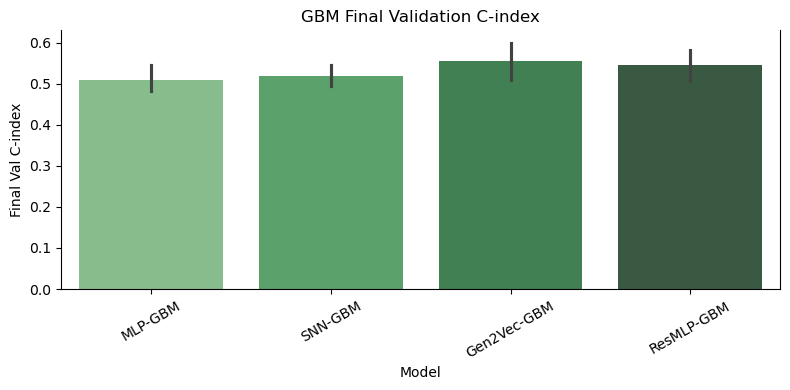

Saved GBM visualization to: result/comparisons/final_cindex_comparison_gbm.png


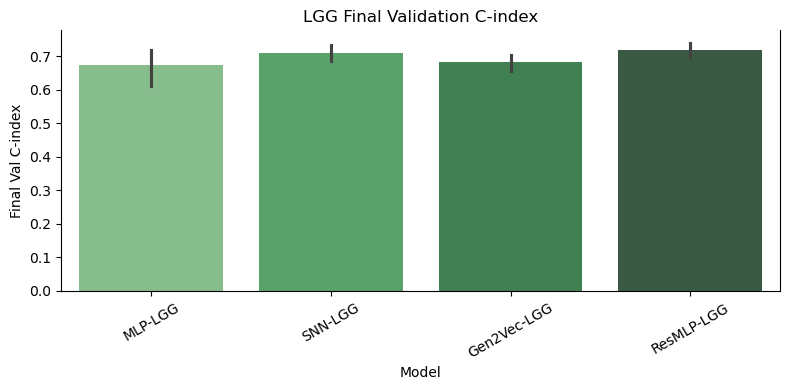

Saved LGG visualization to: result/comparisons/final_cindex_comparison_lgg.png


In [5]:
def print_train_val_loss_accuracy(summary_df):
    metric_columns = [
        "train_loss",
        "final_val_loss",
        "train_cindex",
        "final_val_cindex",
    ]

    fold_df = summary_df.copy()
    if "fold" in fold_df.columns:
        fold_df = fold_df[fold_df["fold"].astype(str).str.lower() != "average"]

    rows = []
    for model_name, model_df in fold_df.groupby("model", dropna=False):
        row = {"Base Line": model_name}
        for metric in metric_columns:
            if metric not in model_df.columns:
                continue

            values = model_df[metric].dropna().astype(float)
            if len(values) == 0:
                row[metric] = "NA"
            elif len(values) == 1:
                row[metric] = f"{values.iloc[0]:.4f}"
            else:
                row[metric] = f"{values.mean():.4f} ± {values.std():.4f}"
        rows.append(row)

    result_df = pd.DataFrame(rows)
    print(result_df.to_string(index=False))
    return result_df


result_df = print_train_val_loss_accuracy(summary_df)
result_df.to_csv("result/comparisons/final_week6.csv")

# Visualize final validation c-index for GBM and LGG separately
plot_df = summary_df.copy()
if "fold" in plot_df.columns:
    plot_df = plot_df[plot_df["fold"].astype(str).str.lower() != "average"]

plot_cols = ["model", "final_val_cindex"]
available_cols = [col for col in plot_cols if col in plot_df.columns]

if len(available_cols) >= 1:
    plot_df = plot_df[[col for col in plot_cols if col in plot_df.columns]].copy()
    plot_df = plot_df.dropna()
    plot_df["dataset"] = plot_df["model"].str.split("-", n=1).str[-1].str.lower()

    if not plot_df.empty:
        for dataset in ["gbm", "lgg"]:
            subset = plot_df[plot_df["dataset"] == dataset]
            if subset.empty:
                print(f"No {dataset.upper()} rows available for plotting.")
                continue

            fig, ax = plt.subplots(1, 1, figsize=(8, 4))
            sns.barplot(data=subset, x="model", y="final_val_cindex", palette="Greens_d", hue="model", legend=False, ax=ax)
            ax.set_title(f"{dataset.upper()} Final Validation C-index")
            ax.set_xlabel("Model")
            ax.set_ylabel("Final Val C-index")
            ax.tick_params(axis="x", rotation=30)
            ax.spines["top"].set_visible(False)

            plt.tight_layout()
            output_dir = Path("result/comparisons")
            output_dir.mkdir(parents=True, exist_ok=True)
            output_path = output_dir / f"final_cindex_comparison_{dataset}.png"
            plt.savefig(output_path, dpi=300, bbox_inches="tight")
            plt.show()
            print(f"Saved {dataset.upper()} visualization to: {output_path}")
    else:
        print("No valid rows available for plotting.")
else:
    print("Required columns for visualization are missing from summary_df.")

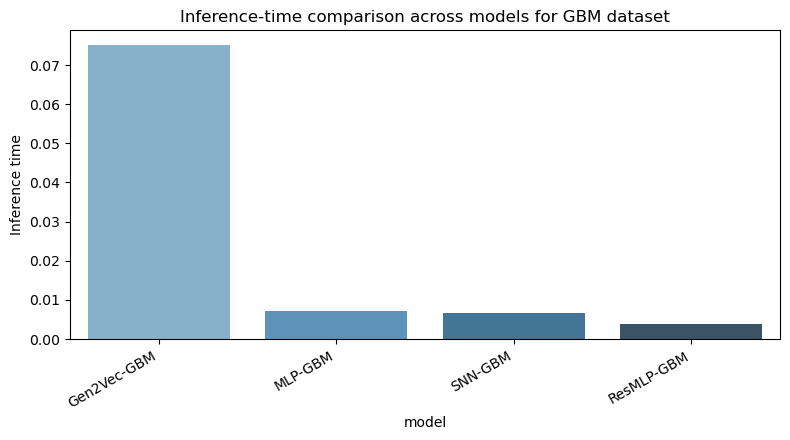

      model  inference_time
Gen2Vec-GBM        0.075119
    MLP-GBM        0.007232
    SNN-GBM        0.006662
 ResMLP-GBM        0.003792
Saved plot to: result/comparisons/inference_time_comparison_gbm.png


In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns

metric_candidates = [
    "inference_time_seconds",
    "inference_time_ms",
    "avg_inference_time_ms",
    "inference_time_ms_per_sample",
    "inference_latency_ms",
]

metric_column = next((col for col in metric_candidates if col in summary_df.columns), None)

if metric_column is None:
    print("No inference-time metrics were found in summary_df.")
else:
    average_summary_df = summary_df.copy()
    if "fold" in average_summary_df.columns:
        average_summary_df = average_summary_df[
            average_summary_df["fold"].astype(str).str.lower() == "average"
        ]

    comparison_df = (
        average_summary_df[["model", metric_column]]
        .dropna()
        .copy()
        .rename(columns={metric_column: "inference_time"})
        .sort_values("inference_time", ascending=False)
    )

    comparison_df = comparison_df[comparison_df["model"].str.contains("GBM", case=False, na=False)]

    plt.figure(figsize=(8, 4.5))
    sns.barplot(data=comparison_df, x="model", y="inference_time", palette="Blues_d", hue="model", legend=False)
    plt.xticks(rotation=30, ha="right")
    plt.ylabel("Inference time")
    plt.title("Inference-time comparison across models for GBM dataset")
    plt.tight_layout()

    output_dir = Path("result/comparisons")
    output_dir.mkdir(parents=True, exist_ok=True)
    output_path = output_dir / "inference_time_comparison_gbm.png"
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()

    print(comparison_df.to_string(index=False))
    print(f"Saved plot to: {output_path}")

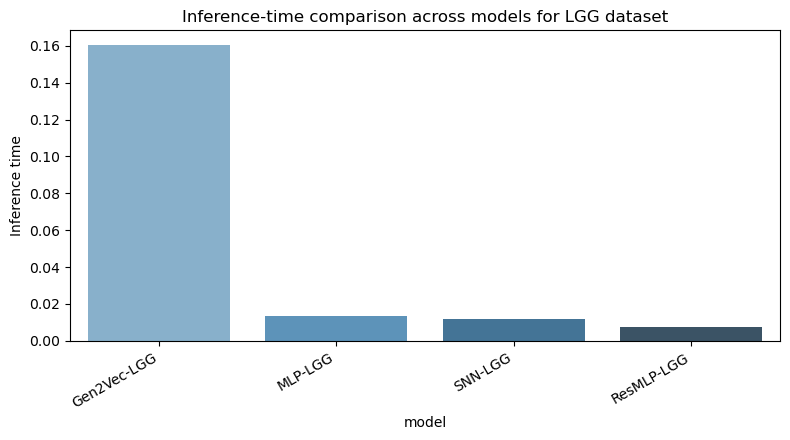

      model  inference_time
Gen2Vec-LGG        0.160348
    MLP-LGG        0.013304
    SNN-LGG        0.011639
 ResMLP-LGG        0.007667
Saved plot to: result/comparisons/inference_time_comparison_lgg.png


In [7]:
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns

metric_candidates = [
    "inference_time_seconds",
    "inference_time_ms",
    "avg_inference_time_ms",
    "inference_time_ms_per_sample",
    "inference_latency_ms",
]

metric_column = next((col for col in metric_candidates if col in summary_df.columns), None)

if metric_column is None:
    print("No inference-time metrics were found in summary_df.")
else:
    average_summary_df = summary_df.copy()
    if "fold" in average_summary_df.columns:
        average_summary_df = average_summary_df[
            average_summary_df["fold"].astype(str).str.lower() == "average"
        ]

    comparison_df = (
        average_summary_df[["model", metric_column]]
        .dropna()
        .copy()
        .rename(columns={metric_column: "inference_time"})
        .sort_values("inference_time", ascending=False)
    )

    comparison_df = comparison_df[comparison_df["model"].str.contains("LGG", case=False, na=False)]

    plt.figure(figsize=(8, 4.5))
    sns.barplot(data=comparison_df, x="model", y="inference_time", palette="Blues_d", hue="model", legend=False)
    plt.xticks(rotation=30, ha="right")
    plt.ylabel("Inference time")
    plt.title("Inference-time comparison across models for LGG dataset")
    plt.tight_layout()

    output_dir = Path("result/comparisons")
    output_dir.mkdir(parents=True, exist_ok=True)
    output_path = output_dir / "inference_time_comparison_lgg.png"
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()

    print(comparison_df.to_string(index=False))
    print(f"Saved plot to: {output_path}")

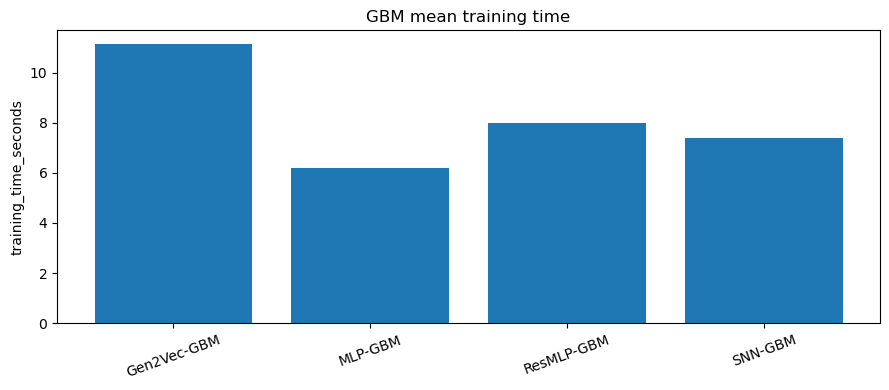

In [8]:
# Mean training time from numeric folds only.
metric_column = next((col for col in ["training_time_seconds", "training_time_per_sample_seconds"]
                      if col in summary_df.columns), None)
if metric_column is None:
    print("No training-time metrics in summaries.")
else:
    numeric_folds = summary_df[pd.to_numeric(summary_df["fold"], errors="coerce").notna()]
    comparison_df = numeric_folds[numeric_folds["model"].str.endswith("-GBM")].groupby("model", as_index=False)[metric_column].mean()
    if not comparison_df.empty:
        fig, ax = plt.subplots(figsize=(9, 4))
        ax.bar(comparison_df["model"], comparison_df[metric_column])
        ax.set(title="GBM mean training time", ylabel=metric_column)
        ax.tick_params(axis="x", rotation=20)
        fig.tight_layout()
        fig.savefig(RESULT_DIR / "comparisons/training_time_comparison_GBM.png", dpi=300)
        plt.show()


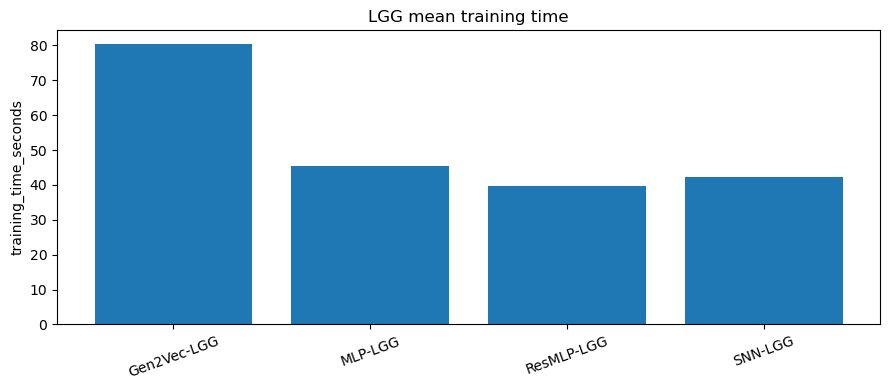

In [9]:
# Mean training time from numeric folds only.
metric_column = next((col for col in ["training_time_seconds", "training_time_per_sample_seconds"]
                      if col in summary_df.columns), None)
if metric_column is None:
    print("No training-time metrics in summaries.")
else:
    numeric_folds = summary_df[pd.to_numeric(summary_df["fold"], errors="coerce").notna()]
    comparison_df = numeric_folds[numeric_folds["model"].str.endswith("-LGG")].groupby("model", as_index=False)[metric_column].mean()
    if not comparison_df.empty:
        fig, ax = plt.subplots(figsize=(9, 4))
        ax.bar(comparison_df["model"], comparison_df[metric_column])
        ax.set(title="LGG mean training time", ylabel=metric_column)
        ax.tick_params(axis="x", rotation=20)
        fig.tight_layout()
        fig.savefig(RESULT_DIR / "comparisons/training_time_comparison_LGG.png", dpi=300)
        plt.show()


In [10]:
# pred = pd.read_csv("/home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/split_mil_lgg_4_predictions.csv")
# y_true = pred["label"].astype(int)
# y_pred = pred["prediction"].astype(int)
# class_names = sorted(set(y_true).union(set(y_pred)))
# cm = confusion_matrix(y_true, y_pred, labels=class_names)

# output_dir = Path("result/comparisons")
# output_dir.mkdir(parents=True, exist_ok=True)
# output_path = output_dir / "MIL_confusion_LGG.png"

# plt.figure(figsize=(5, 4))
# sns.heatmap(
#     cm,
#     annot=True,
#     fmt="d",
#     cmap="Blues",
#     xticklabels=class_names,
#     yticklabels=class_names,
# )
# plt.title("MIL Confusion Matrix for LGG")
# plt.xlabel("Predicted class")
# plt.ylabel("True class")
# plt.tight_layout()
# plt.savefig(output_path, dpi=300, bbox_inches="tight")
# plt.show()

# print(f"Saved confusion matrix to: {output_path}")


In [11]:
# pred = pd.read_csv("/home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/split_mil_gbm_own_4_predictions.csv")
# y_true = pred["label"].astype(int)
# y_pred = pred["prediction"].astype(int)
# class_names = sorted(set(y_true).union(set(y_pred)))
# cm = confusion_matrix(y_true, y_pred, labels=class_names)

# output_dir = Path("result/comparisons")
# output_dir.mkdir(parents=True, exist_ok=True)
# output_path = output_dir / "mlp_confusion.png"

# plt.figure(figsize=(5, 4))
# sns.heatmap(
#     cm,
#     annot=True,
#     fmt="d",
#     cmap="Blues",
#     xticklabels=class_names,
#     yticklabels=class_names,
# )
# plt.title("MIL Confusion Matrix For GBM")
# plt.xlabel("Predicted class")
# plt.ylabel("True class")
# plt.tight_layout()
# plt.savefig(output_path, dpi=300, bbox_inches="tight")
# plt.show()

# print(f"Saved confusion matrix to: {output_path}")


In [12]:
# Read model-specific histories, never unrelated shared checkpoint histories.
history_dir = RESULT_DIR / "resmlp" / DATA_FILE
history_frames = []
for history_path in sorted(history_dir.glob("training_history_fold_*.csv")):
    history = pd.read_csv(history_path)
    history["fold"] = history_path.stem.rsplit("_", 1)[-1]
    history["epoch"] = range(1, len(history) + 1)
    history_frames.append(history)
df = pd.concat(history_frames, ignore_index=True) if history_frames else pd.DataFrame()


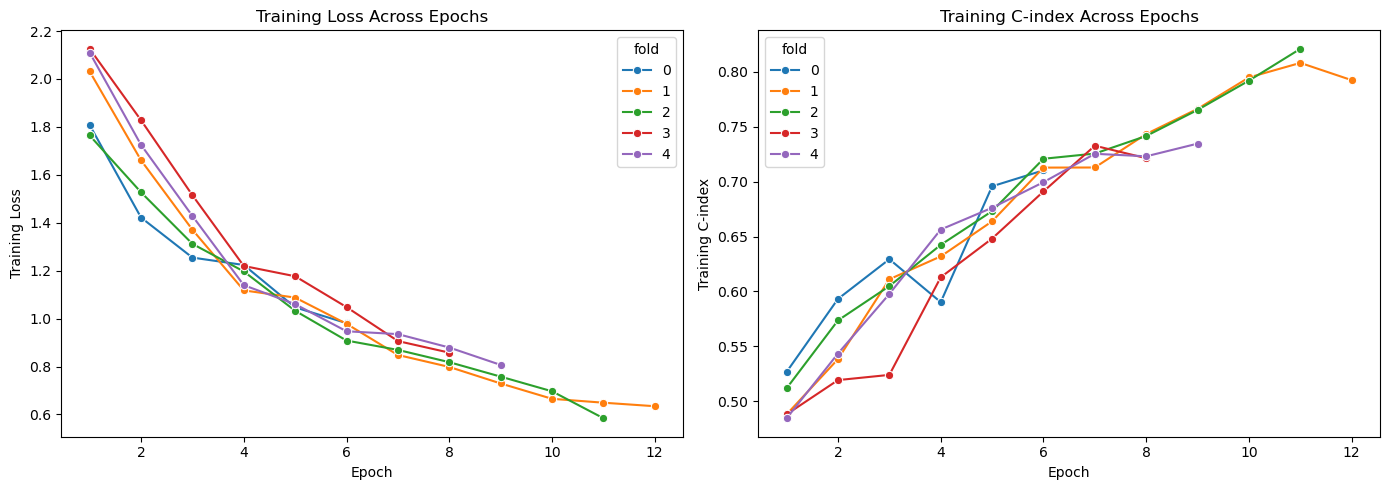

Saved training history plot to: result/comparisons/training_history_across_folds.png


In [13]:
if df.empty:
    print("No training history data found. Please check result/model_checkpoints/training_history_fold_1.csv")
else:
    required_cols = {"train_loss", "train_cindex"}
    missing_cols = sorted(required_cols - set(df.columns))

    if missing_cols:
        print(f"Cannot plot training history. Missing columns: {missing_cols}")
        print(f"Available columns: {list(df.columns)}")
    else:
        plot_df = df.copy()
        if "fold" not in plot_df.columns:
            plot_df["fold"] = "fold_0"
        plot_df["fold"] = plot_df["fold"].astype(str)

        if "epoch" not in plot_df.columns:
            plot_df["epoch"] = plot_df.groupby("fold").cumcount() + 1

        fig, axes = plt.subplots(1, 2, figsize=(14, 5))

        sns.lineplot(
            data=plot_df,
            x="epoch",
            y="train_loss",
            hue="fold",
            marker="o",
            ax=axes[0],
        )
        axes[0].set_title("Training Loss Across Epochs")
        axes[0].set_xlabel("Epoch")
        axes[0].set_ylabel("Training Loss")

        sns.lineplot(
            data=plot_df,
            x="epoch",
            y="train_cindex",
            hue="fold",
            marker="o",
            ax=axes[1],
        )
        axes[1].set_title("Training C-index Across Epochs")
        axes[1].set_xlabel("Epoch")
        axes[1].set_ylabel("Training C-index")

        plt.tight_layout()
        output_dir = Path("result/comparisons")
        output_dir.mkdir(parents=True, exist_ok=True)
        output_path = output_dir / "training_history_across_folds.png"
        plt.savefig(output_path, dpi=300, bbox_inches="tight")
        plt.show()
        print(f"Saved training history plot to: {output_path}")


# ResMLP results for the poster
Final training and validation loss/C-index are summarized across folds for GBM and LGG. Error bars represent sample standard deviations across folds. Confusion matrices use **validation** predictions from one selected fold, because training prediction files are not available. Figures are exported as 300-DPI PNG and vector PDF files.


In [14]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

POSTER_ROOT = Path.cwd().resolve()
if not (POSTER_ROOT / "result").is_dir():
    POSTER_ROOT = POSTER_ROOT.parent
POSTER_DIR = POSTER_ROOT / "result/comparisons/resmlp_poster"
POSTER_DIR.mkdir(parents=True, exist_ok=True)
RESMLP_DATASETS = {"GBM": "normalized_zscore_gbm.csv", "LGG": "normalized_zscore_lgg.csv"}
RESMLP_FOLD = 2  # One held-out validation fold for the confusion matrices.

def save_resmlp_figure(fig, name):
    for extension in ("png", "pdf"):
        fig.savefig(POSTER_DIR / f"{name}.{extension}", dpi=300, bbox_inches="tight", facecolor="white")
    print("Saved:", POSTER_DIR / name)

resmlp_frames = []
for cohort, dataset in RESMLP_DATASETS.items():
    frame = pd.read_csv(POSTER_ROOT / "result/resmlp" / dataset / "summary.csv")
    frame = frame[pd.to_numeric(frame["fold"], errors="coerce").notna()].copy()
    frame["fold"] = frame["fold"].astype(int)
    frame["Cohort"] = cohort
    resmlp_frames.append(frame)
resmlp_folds = pd.concat(resmlp_frames, ignore_index=True)
resmlp_metrics = ["train_cindex", "final_val_cindex", "train_loss", "final_val_loss"]
resmlp_stats = resmlp_folds.groupby("Cohort", sort=False)[resmlp_metrics].agg(["mean", "std"])
display(resmlp_stats.round(4))
resmlp_stats.to_csv(POSTER_DIR / "resmlp_mean_std.csv")
resmlp_folds.to_csv(POSTER_DIR / "resmlp_fold_results.csv", index=False)


train_cindex         final_val_cindex         train_loss          \
               mean     std             mean     std       mean     std   
Cohort                                                                    
GBM          0.6281  0.0971           0.5459  0.0471     1.2438  0.4096   
LGG          0.8832  0.0120           0.7198  0.0278     0.0300  0.0061   

       final_val_loss         
                 mean    std  
Cohort                        
GBM             1.701  0.098  
LGG             2.833  0.351

Saved: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/comparisons/resmlp_poster/resmlp_training_validation_cindex


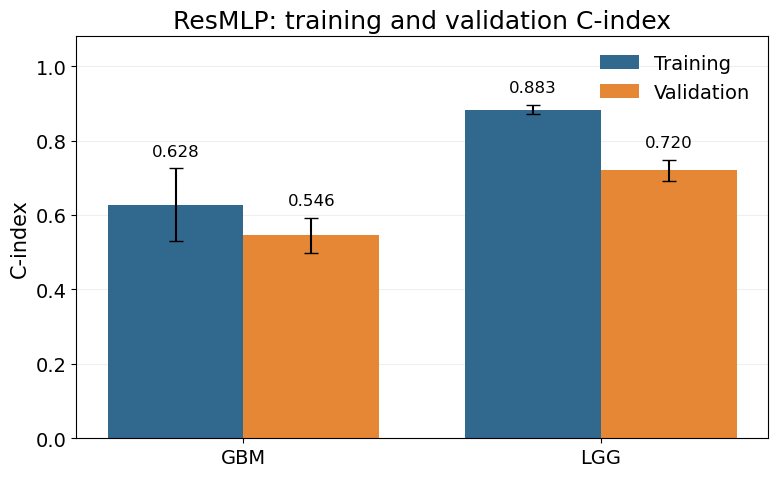

Saved: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/comparisons/resmlp_poster/resmlp_training_validation_loss


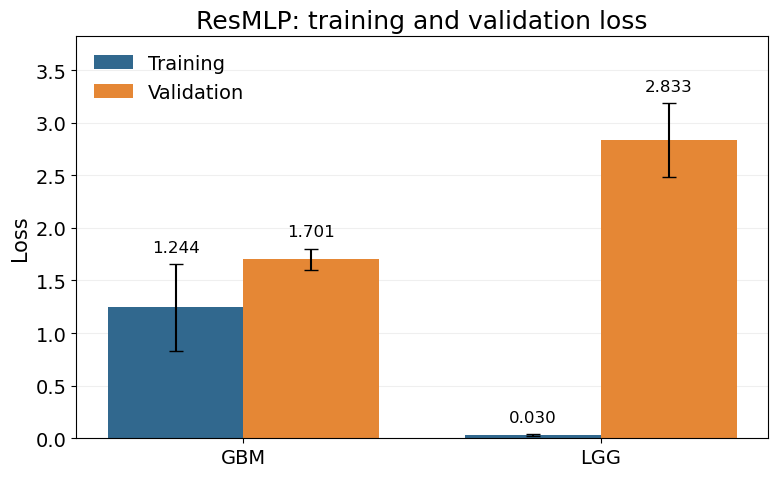

In [15]:
# Separate, large-label figures for poster placement.
with plt.rc_context({"font.size": 14, "axes.titlesize": 18, "axes.labelsize": 15}):
    for metric, ylabel, title in [
        ("cindex", "C-index", "ResMLP: training and validation C-index"),
        ("loss", "Loss", "ResMLP: training and validation loss"),
    ]:
        fig, ax = plt.subplots(figsize=(8, 5))
        x = np.arange(len(RESMLP_DATASETS))
        for offset, column, label, color in [
            (-0.19, f"train_{metric}", "Training", "#31688e"),
            (0.19, f"final_val_{metric}", "Validation", "#e58735"),
        ]:
            means = resmlp_stats[(column, "mean")]
            stds = resmlp_stats[(column, "std")].fillna(0)
            bars = ax.bar(x + offset, means, width=0.38, yerr=stds, capsize=5, label=label, color=color)
            ax.bar_label(bars, fmt="%.3f", padding=7, fontsize=12)
        ax.set(xticks=x, xticklabels=list(RESMLP_DATASETS), ylabel=ylabel, title=title)
        if metric == "cindex":
            ax.set_ylim(0, 1.08)
        else:
            ax.set_ylim(0, max((resmlp_stats[(c, "mean")] + resmlp_stats[(c, "std")].fillna(0)).max()
                             for c in ["train_loss", "final_val_loss"]) * 1.2)
        ax.legend(frameon=False)
        ax.grid(axis="y", alpha=0.2)
        ax.set_axisbelow(True)
        fig.tight_layout()
        save_resmlp_figure(fig, f"resmlp_training_validation_{metric}")
        plt.show()


Saved: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/comparisons/resmlp_poster/resmlp_gbm_validation_fold_2_confusion_matrix


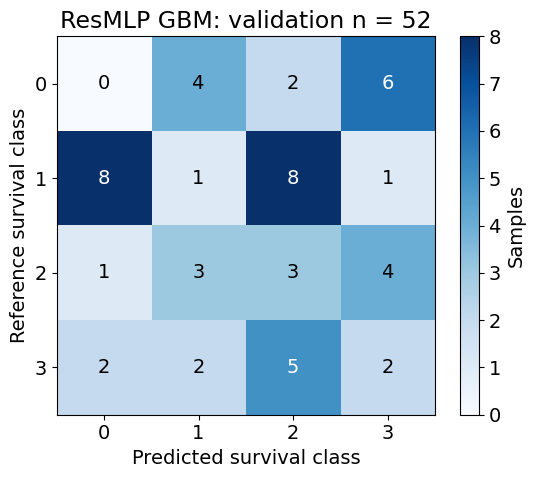

Saved: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/comparisons/resmlp_poster/resmlp_lgg_validation_fold_2_confusion_matrix


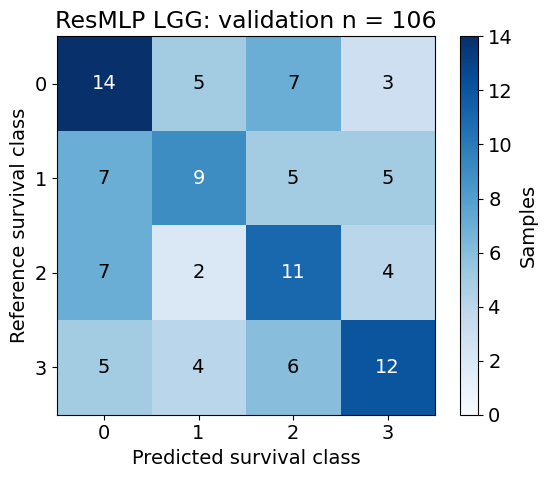

Training confusion matrices require saved training predictions; these figures show validation only.


In [16]:
with plt.rc_context({"font.size": 14, "axes.titlesize": 17}):
    resmlp_validation_counts = {}
    for cohort, dataset in RESMLP_DATASETS.items():
        fig, ax = plt.subplots(figsize=(6, 5))
        path = POSTER_ROOT / "result" / f"split_resmlp_{dataset}_{RESMLP_FOLD}_predictions.csv"
        predictions = pd.read_csv(path)
        matrix = pd.crosstab(predictions["label"], predictions["prediction"]).reindex(
            index=range(4), columns=range(4), fill_value=0).to_numpy()
        assert matrix.sum() == len(predictions), "Unexpected prediction class labels."
        resmlp_validation_counts[cohort] = len(predictions)
        accuracy = (predictions["label"] == predictions["prediction"]).mean()
        heat = ax.imshow(matrix, cmap="Blues", vmin=0)
        for row in range(4):
            for col in range(4):
                ax.text(col, row, matrix[row, col], ha="center", va="center",
                        color="white" if matrix[row, col] > matrix.max() / 2 else "black")
        ax.set(xticks=range(4), yticks=range(4), xlabel="Predicted survival class",
               ylabel="Reference survival class",
               title=f"ResMLP {cohort}: validation n = {len(predictions)}")
        fig.colorbar(heat, ax=ax, label="Samples", fraction=0.046)
        fig.tight_layout()
        save_resmlp_figure(fig, f"resmlp_{cohort.lower()}_validation_fold_{RESMLP_FOLD}_confusion_matrix")
        plt.show()
print("Training confusion matrices require saved training predictions; these figures show validation only.")


## ResMLP training and validation comparison
Run these cells independently. Select the dataset below; every fold in its summary is included. Final metrics compare the saved training and held-out validation results. If early-stopping histories contain `monitor_loss`, its curve is shown separately from the outer validation result. Historical runs with training-only histories have one final validation point, not a per-epoch validation curve.


,fold,train_loss,final_val_loss,train_cindex,final_val_cindex,C-index gap (train - validation)
0,0,1.8076,1.7767,0.5267,0.5064,0.0203
1,1,0.8483,1.7112,0.7128,0.5938,0.1191
2,2,0.9085,1.5321,0.7208,0.4861,0.2347
3,3,1.5148,1.7245,0.5240,0.5633,-0.0393
4,4,1.1396,1.7605,0.6563,0.5797,0.0766


Mean training loss: 1.244
Mean validation loss: 1.701
Mean training C-index: 0.628
Mean validation C-index: 0.546


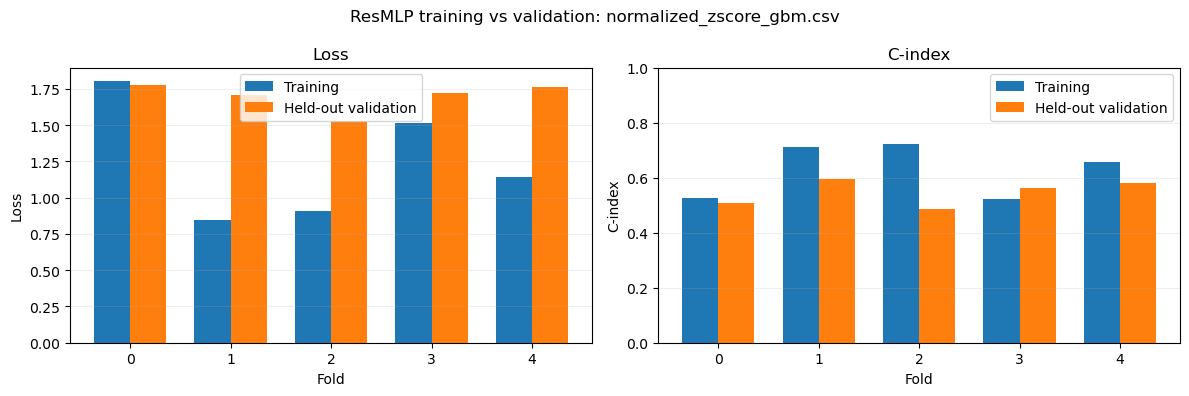

In [17]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

COMPARE_ROOT = Path.cwd().resolve()
if not (COMPARE_ROOT / "result").is_dir():
    COMPARE_ROOT = COMPARE_ROOT.parent
COMPARE_DATASET = "normalized_zscore_gbm.csv"  # Change to normalized_zscore_lgg.csv for LGG.
COMPARE_DIR = COMPARE_ROOT / "result/resmlp" / COMPARE_DATASET
COMPARE_OUTPUT = COMPARE_ROOT / "result/comparisons/resmlp_poster"
COMPARE_OUTPUT.mkdir(parents=True, exist_ok=True)
compare_summary = pd.read_csv(COMPARE_DIR / "summary.csv")
compare_folds = compare_summary[pd.to_numeric(compare_summary["fold"], errors="coerce").notna()].copy()
compare_folds["fold"] = compare_folds["fold"].astype(int)
compare_folds = compare_folds.sort_values("fold")
compare_table = compare_folds[["fold", "train_loss", "final_val_loss", "train_cindex", "final_val_cindex"]].copy()
compare_table["C-index gap (train - validation)"] = compare_table["train_cindex"] - compare_table["final_val_cindex"]
display(compare_table.round(4))
for column, label in [("train_loss", "Mean training loss"), ("final_val_loss", "Mean validation loss"),
                      ("train_cindex", "Mean training C-index"), ("final_val_cindex", "Mean validation C-index")]:
    print(f"{label}: {compare_folds[column].mean():.3f}")

def save_comparison(fig, suffix):
    for extension in ["png", "pdf"]:
        fig.savefig(COMPARE_OUTPUT / f"resmlp_{COMPARE_DATASET}_{suffix}.{extension}", dpi=300, bbox_inches="tight")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(compare_folds))
for ax, train_col, val_col, title in [
    (axes[0], "train_loss", "final_val_loss", "Loss"),
    (axes[1], "train_cindex", "final_val_cindex", "C-index"),
]:
    ax.bar(x - 0.18, compare_folds[train_col], width=0.36, label="Training")
    ax.bar(x + 0.18, compare_folds[val_col], width=0.36, label="Held-out validation")
    ax.set(title=title, xlabel="Fold", ylabel=title, xticks=x, xticklabels=compare_folds["fold"])
    ax.legend()
    ax.grid(axis="y", alpha=0.2)
axes[1].set_ylim(0, 1)
fig.suptitle(f"ResMLP training vs validation: {COMPARE_DATASET}")
fig.tight_layout()
save_comparison(fig, "fold_comparison")
plt.show()


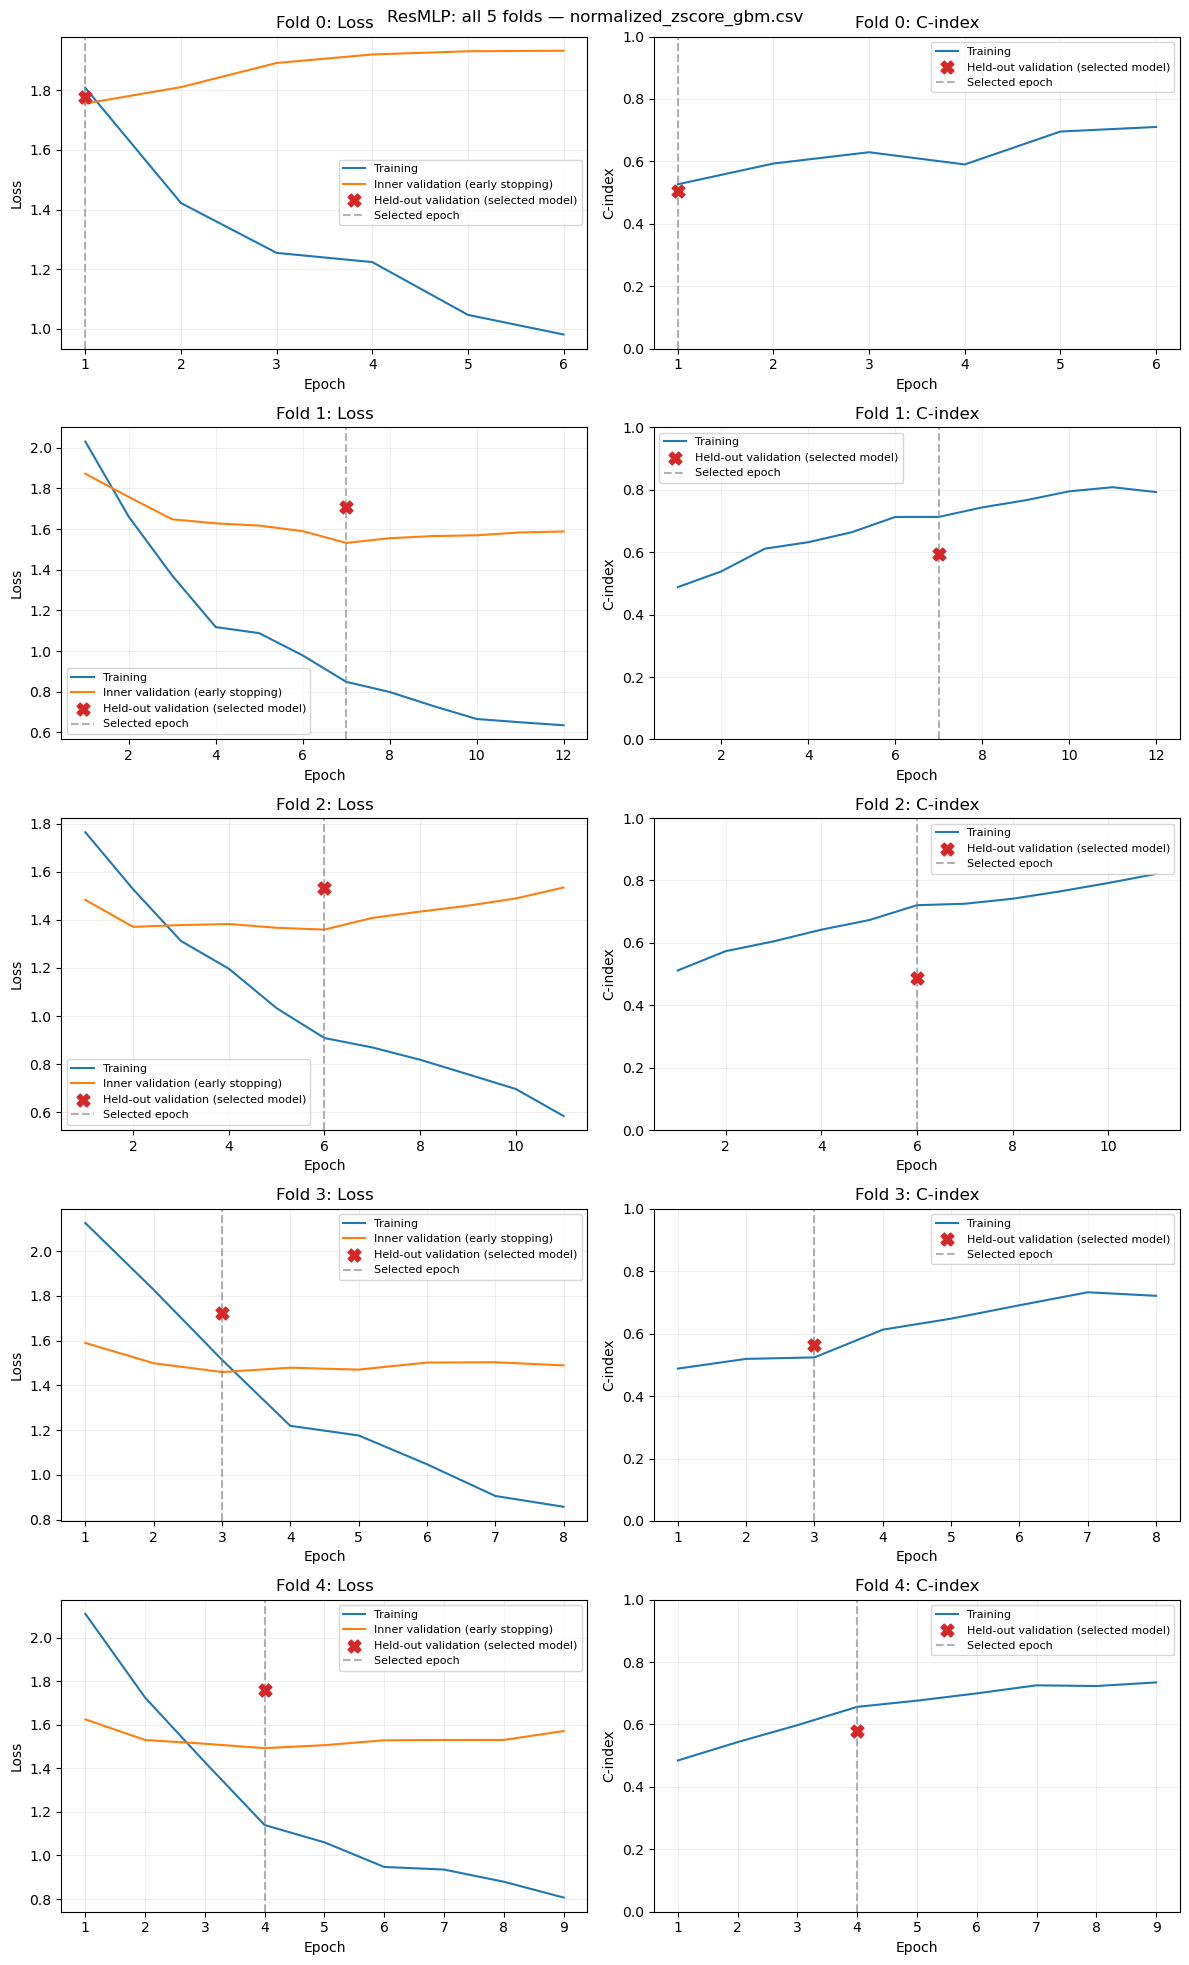

Validation markers are final held-out evaluations; only monitor_loss is recorded each epoch.


In [18]:
# Compare training and validation for every fold in the saved summary.
fig, axes = plt.subplots(len(compare_folds), 2, figsize=(12, 4 * len(compare_folds)), squeeze=False)
for index, (_, selected_row) in enumerate(compare_folds.iterrows()):
    fold = int(selected_row["fold"])
    history_path = COMPARE_DIR / f"training_history_fold_{fold}.csv"
    history = pd.read_csv(history_path) if history_path.exists() else pd.DataFrame()
    selected_epoch = int(history["selected_epoch"].iloc[-1]) if not history.empty and "selected_epoch" in history else len(history)
    matches = (not history.empty and {"train_loss", "train_cindex"}.issubset(history.columns)
               and 1 <= selected_epoch <= len(history) and np.allclose(
                   history.iloc[selected_epoch - 1][["train_loss", "train_cindex"]].to_numpy(float),
                   [selected_row["train_loss"], selected_row["train_cindex"]], rtol=1e-4, atol=1e-6))
    if not matches:
        # Final metrics remain available even when the epoch history is missing or stale.
        print(f"Fold {fold}: no matching epoch history; showing final metrics.")
    for ax, training, final, ylabel in [
        (axes[index, 0], "train_loss", "final_val_loss", "Loss"),
        (axes[index, 1], "train_cindex", "final_val_cindex", "C-index"),
    ]:
        if matches:
            epochs = np.arange(1, len(history) + 1)
            ax.plot(epochs, history[training], label="Training")
            if ylabel == "Loss" and "monitor_loss" in history:
                ax.plot(epochs, history["monitor_loss"], label="Inner validation (early stopping)")
            ax.scatter(selected_epoch, selected_row[final], s=85, marker="X", color="tab:red", label="Held-out validation (selected model)", zorder=5)
            ax.axvline(selected_epoch, linestyle="--", color="gray", alpha=0.6, label="Selected epoch")
            ax.set_xlabel("Epoch")
        else:
            ax.bar(["Training", "Validation"], [selected_row[training], selected_row[final]], color=["tab:blue", "tab:red"])
        ax.set(ylabel=ylabel, title=f"Fold {fold}: {ylabel}")
        if matches:
            ax.legend(fontsize=8)
        ax.grid(alpha=0.2)
    axes[index, 1].set_ylim(0, 1)
fig.suptitle(f"ResMLP: all {len(compare_folds)} folds — {COMPARE_DATASET}")
fig.tight_layout()
save_comparison(fig, "all_folds_learning_curves")
plt.show()
print("Validation markers are final held-out evaluations; only monitor_loss is recorded each epoch.")


## Mean training time: SNN, MLP, Gen2Vec, and ResMLP
One bar per model shows total training time averaged across saved folds. The precomputed `average` row is excluded. Compare runs with equivalent hardware, epoch budgets, and data splits; these saved times may reflect different settings or early stopping.


,Model,Folds,Mean training time (seconds)
0,SNN,5,7.375
1,MLP,5,6.208
2,Gen2Vec,5,11.130
3,ResMLP,5,7.982


Saved: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/comparisons/genomic_models/normalized_zscore_gbm.csv_mean_training_time.png
Saved: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/comparisons/genomic_models/normalized_zscore_gbm.csv_mean_training_time.pdf


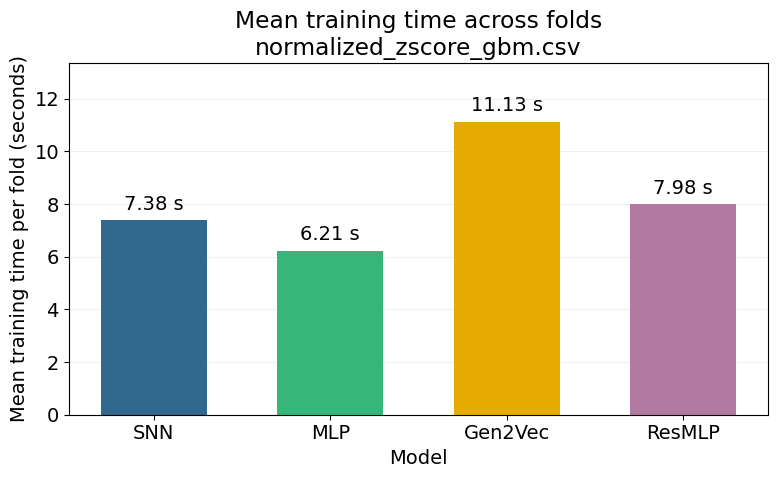

In [19]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

TIME_ROOT = Path.cwd().resolve()
if not (TIME_ROOT / "result").is_dir():
    TIME_ROOT = TIME_ROOT.parent
TIME_DATASET = globals().get("COMPARE_DATASET", "normalized_zscore_gbm.csv")
TIME_MODELS = {"SNN": "snn", "MLP": "mlp", "Gen2Vec": "gen2vec", "ResMLP": "resmlp"}
time_rows = []
for label, folder in TIME_MODELS.items():
    summary_path = TIME_ROOT / "result" / folder / TIME_DATASET / "summary.csv"
    summary = pd.read_csv(summary_path)
    fold_rows = summary[pd.to_numeric(summary["fold"], errors="coerce").notna()]
    times = pd.to_numeric(fold_rows["training_time_seconds"], errors="coerce")
    if times.empty or times.isna().any() or (times < 0).any():
        raise ValueError(f"Missing or invalid fold training times: {summary_path}")
    time_rows.append({"Model": label, "Folds": len(times), "Mean training time (seconds)": times.mean()})
time_comparison = pd.DataFrame(time_rows)
display(time_comparison.round(3))

with plt.rc_context({"font.size": 14}):
    fig, ax = plt.subplots(figsize=(8, 5))
    bars = ax.bar(time_comparison["Model"], time_comparison["Mean training time (seconds)"],
                  color=["#31688e", "#35b779", "#e6ab02", "#b279a2"], width=0.6)
    ax.bar_label(bars, fmt="%.2f s", padding=5)
    ax.set(ylabel="Mean training time per fold (seconds)", xlabel="Model",
           title=f"Mean training time across folds\n{TIME_DATASET}")
    ax.set_ylim(0, time_comparison["Mean training time (seconds)"].max() * 1.2)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    fig.tight_layout()
    time_output = TIME_ROOT / "result/comparisons/genomic_models"
    time_output.mkdir(parents=True, exist_ok=True)
    for extension in ["png", "pdf"]:
        path = time_output / f"{TIME_DATASET}_mean_training_time.{extension}"
        fig.savefig(path, dpi=300, bbox_inches="tight")
        print("Saved:", path)
    time_comparison.to_csv(time_output / f"{TIME_DATASET}_mean_training_time.csv", index=False)
    plt.show()


In [20]:
# combination of wsi metadata file for lgg and gbm